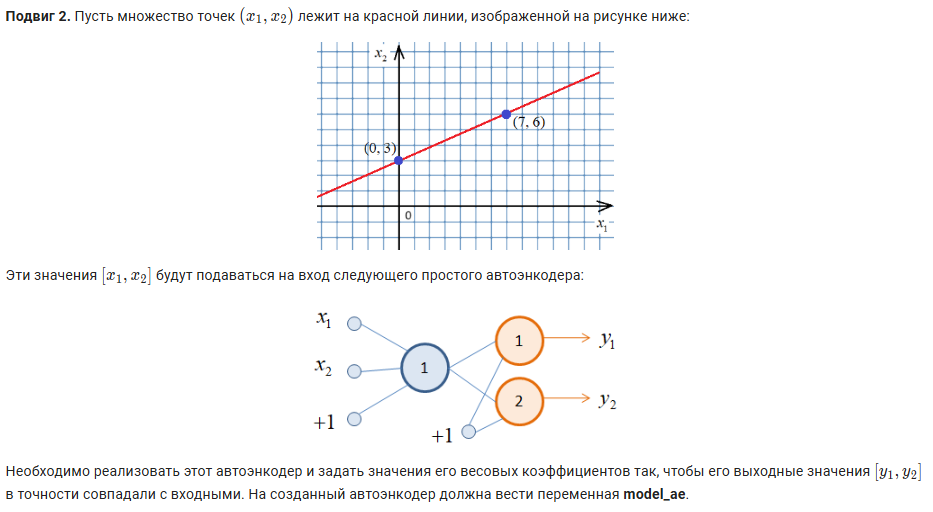

In [39]:
import torch
import torch.nn as nn

model_ae = nn.Sequential()

model_ae.add_module('iin', nn.Linear(2, 1))
model_ae.add_module('oout', nn.Linear(1, 2))

model_ae.iin.weight.data = torch.tensor([[1., 0.]], dtype=torch.float32)
model_ae.iin.bias.data = torch.tensor([0.], dtype=torch.float32)

model_ae.oout.weight.data = torch.tensor([[1.], [3/7]], dtype=torch.float32)
model_ae.oout.bias.data = torch.tensor([0., 3.], dtype=torch.float32)

model_ae.eval()

x = torch.tensor([[0., 3.]], dtype=torch.float32)
model_ae(x)


tensor([[0., 3.]], grad_fn=<AddmmBackward0>)

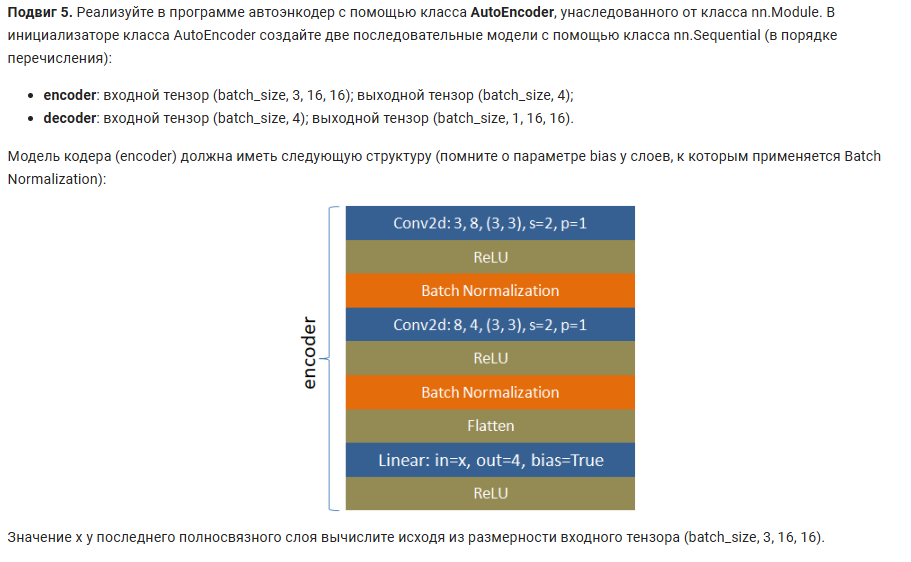

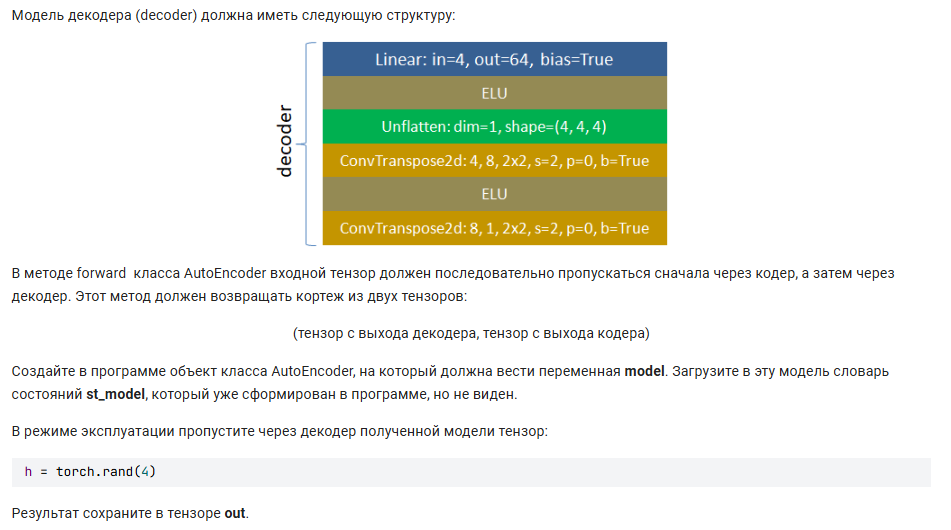

In [56]:
import torch
import torch.nn as nn

# здесь объявляйте класс модели (обязательно до тензора)
class AutoEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=8, kernel_size=(3, 3), stride=2, padding=1, bias=False),
            nn.ReLU(),
            nn.BatchNorm2d(8),
            nn.Conv2d(in_channels=8, out_channels=4, kernel_size=(3, 3), stride=2, padding=1, bias=False),
            nn.ReLU(),
            nn.BatchNorm2d(4),
            nn.Flatten(),
            nn.Linear(64, 4, bias=True),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(4, 64, bias=True),
            nn.ELU(),
            nn.Unflatten(dim=1, unflattened_size=(4, 4, 4)),
            nn.ConvTranspose2d(in_channels=4, out_channels=8, kernel_size=(2, 2), stride=2, padding=0, bias=True),
            nn.ELU(),
            nn.ConvTranspose2d(in_channels=8, out_channels=1, kernel_size=(2, 2), stride=2, padding=0, bias=True),
            
        )

    def forward(self, x):
        h = self.encoder(x)
        out = self.decoder(h)
        return out, h

h = torch.rand(4) # тензор h в программе не менять
model = AutoEncoder()
try:
    model.load_state_dict(st_model)
except:
    pass
    
model.eval()
out = model.decoder(h.unsqueeze(0))
out
# здесь продолжайте программу

tensor([[[[0.4307, 0.3240, 0.4191, 0.2623, 0.3149, 0.2339, 0.2966, 0.2624,
           0.3852, 0.2940, 0.3781, 0.2329, 0.3426, 0.2762, 0.3794, 0.3047],
          [0.2598, 0.5622, 0.2539, 0.5575, 0.3274, 0.4700, 0.3622, 0.4291,
           0.2529, 0.5328, 0.2711, 0.5160, 0.3298, 0.4363, 0.2598, 0.4913],
          [0.3296, 0.2432, 0.3123, 0.2441, 0.3599, 0.2888, 0.3956, 0.3040,
           0.3395, 0.2596, 0.3292, 0.2547, 0.3586, 0.2761, 0.3362, 0.2276],
          [0.2389, 0.5810, 0.2733, 0.4044, 0.3366, 0.4561, 0.3179, 0.4412,
           0.2653, 0.5453, 0.2610, 0.4556, 0.3222, 0.3964, 0.3517, 0.4421],
          [0.3750, 0.2845, 0.3643, 0.2267, 0.3186, 0.2578, 0.2982, 0.1152,
           0.2745, 0.2466, 0.3366, 0.2537, 0.3038, 0.2447, 0.3160, 0.2238],
          [0.2510, 0.5137, 0.2820, 0.4905, 0.2026, 0.6138, 0.2982, 0.5201,
           0.3089, 0.4178, 0.2478, 0.4734, 0.2810, 0.4564, 0.2987, 0.4462],
          [0.3429, 0.2611, 0.3354, 0.2640, 0.3578, 0.3077, 0.3717, 0.2817,
           0.3712, 

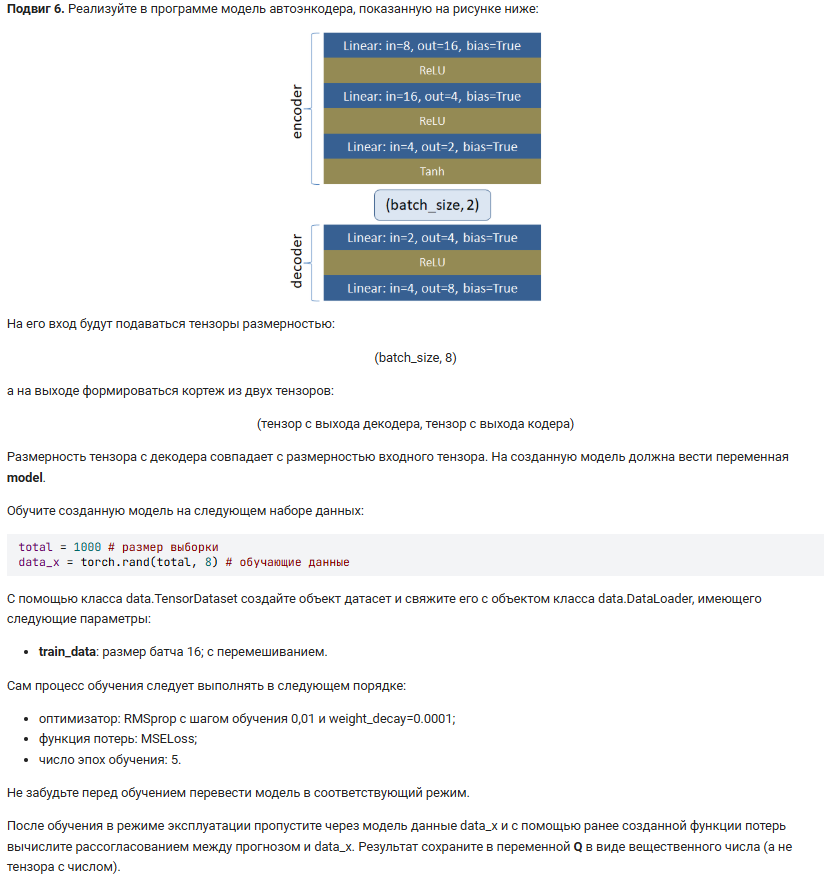

In [82]:
import torch
import torch.nn as nn
import torch.utils.data as data
import torch.optim as optim

# здесь объявляйте класс модели
class AutoEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(8, 16),
            nn.ReLU(),
            nn.Linear(16, 4),
            nn.ReLU(),
            nn.Linear(4, 2),
            nn.Tanh()
        )
        self.decoder = nn.Sequential(
            nn.Linear(2, 4),
            nn.ReLU(),
            nn.Linear(4, 8),
        )

    def forward(self, x):
        h = self.encoder(x)
        out = self.decoder(h)
        return out, h
        

total = 1000 # размер выборки
data_x = torch.rand(total, 8) # обучающие данные
dataset = data.TensorDataset(data_x)
train_data = data.DataLoader(dataset, batch_size=16, shuffle=True)

model = AutoEncoder()
model.train()

optimizer = optim.RMSprop(params=model.parameters(), lr=0.01, weight_decay=0.0001)
loss_func = nn.MSELoss()
epochs = 5

# здесь продолжайте программу

for e in range(epochs):
    for x_train in train_data:
        x_train = x_train[0]
        pred = model(x_train)[0]
        loss = loss_func(pred, x_train)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
model.eval()
Q = loss_func(model(data_x)[0], data_x).item()
Q



0.0720701813697815